# S03-A1 — RQ01 a RQ04: mediana e IQR de cada métrica

Notebook reexecutável a partir das fontes congeladas da S02, sem token e sem nova coleta:

- `data/dataset.csv` e `data/amostra_final.csv`, conferidos pelos hashes dos manifestos;
- `data/fontes_s02.zip`, de onde os episódios de recuperação são recalculados com
  `metricas.recuperacao` e conferidos contra o dataset.

O cálculo está em `analises/rq01_04.py`. O comando `python -m analises.sprint3_a` grava os
mesmos resultados em `results/s03_a/`; este notebook recalcula tudo e **falha** se algum CSV
publicado divergir.

Regras da análise:

- uma observação por repositório, sem ponderar por número de commits ou runs;
- mediana e IQR (Q1–Q3, interpolação linear), nunca média e desvio-padrão;
- ausências continuam ausentes: os 11 CFR (b) indisponíveis e os 22 projetos sem episódio
  observável não viram zero;
- episódios censurados (falha sem sucesso posterior) não têm duração e são contados à parte.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import pandas as pd
from IPython.display import Image, display

from analises import rq01_04
from analises.entrada import carregar_dataset, carregar_episodios
from analises.sprint3_a import conferir_publicado

PUBLICADOS = Path("results/s03_a")
pd.set_option("display.width", 160)

df, origens = carregar_dataset()
episodios, pacote_sha256 = carregar_episodios(df)
tabelas = rq01_04.analisar(df, episodios)
for nome, tabela in tabelas.items():
    conferir_publicado(tabela, PUBLICADOS / f"{nome}.csv")
print(f"{len(df)} repositórios; {len(episodios)} episódios concluídos recalculados dos runs")
print("dataset", origens["dataset_sha256"][:16], "| fontes_s02.zip", pacote_sha256[:16])
print("CSVs publicados conferidos:", ", ".join(tabelas))

300 repositórios; 7771 episódios concluídos recalculados dos runs
dataset 8c494ec09f475e7f | fontes_s02.zip bf26c9a146a0823b
CSVs publicados conferidos: rq01_04_descritivas, rq01_04_pareadas, rq04_censura, rq04_episodios


## Mediana e IQR por métrica e variante

Frequência em entregas por semana (janela inclusiva de 01/10/2025 a 30/09/2026), lead time e
recuperação em horas, CFR como proporção de 0 a 1. A última linha agrega todos os episódios
concluídos; as demais têm um valor por projeto.

In [2]:
colunas = ["rq", "rotulo", "n", "n_ausentes", "mediana", "q1", "q3", "iqr", "minimo", "maximo"]
tabelas["rq01_04_descritivas"][colunas].round(4)

,rq,rotulo,n,n_ausentes,mediana,q1,q3,iqr,minimo,maximo
0,RQ01,Frequência: releases,300,0,0.3260,0.1534,0.8247,0.6712,0.0959,14.3644
1,RQ01,Frequência: com pré-releases,300,0,0.3452,0.1726,0.8630,0.6904,0.0959,71.7068
2,RQ01,Frequência: tags,300,0,0.4027,0.1918,1.0164,0.8247,0.0959,76.3288
3,RQ02,Lead time (a): por release,300,0,196.6972,47.2604,715.5859,668.3255,0.0006,40129.7747
4,RQ02,Lead time (b): por commit,300,0,178.3077,43.1006,475.4280,432.3275,0.0006,34894.6300
5,RQ03,CFR (a): runs de CI,300,0,0.0548,0.0238,0.1287,0.1049,0.0000,0.9529
6,RQ03,CFR (b): releases,289,11,0.1750,0.0000,0.4286,0.4286,0.0000,1.0000
7,RQ04,Recuperação: mediana por projeto,278,22,3.2018,0.6048,18.3743,17.7695,0.0450,2627.0225
8,RQ04,Recuperação: episódios concluídos,7771,90,3.5667,0.8789,20.2824,19.4035,0.0053,6019.3567


## Distribuições

Caixas: Q1, mediana e Q3; bigodes nos percentis 5 e 95. Cada ponto é um projeto; para os
episódios, só os valores fora de P5–P95 aparecem como pontos. As linhas tracejadas são os
cortes da classificação DORA de referência (`metricas/classificacao.py`).

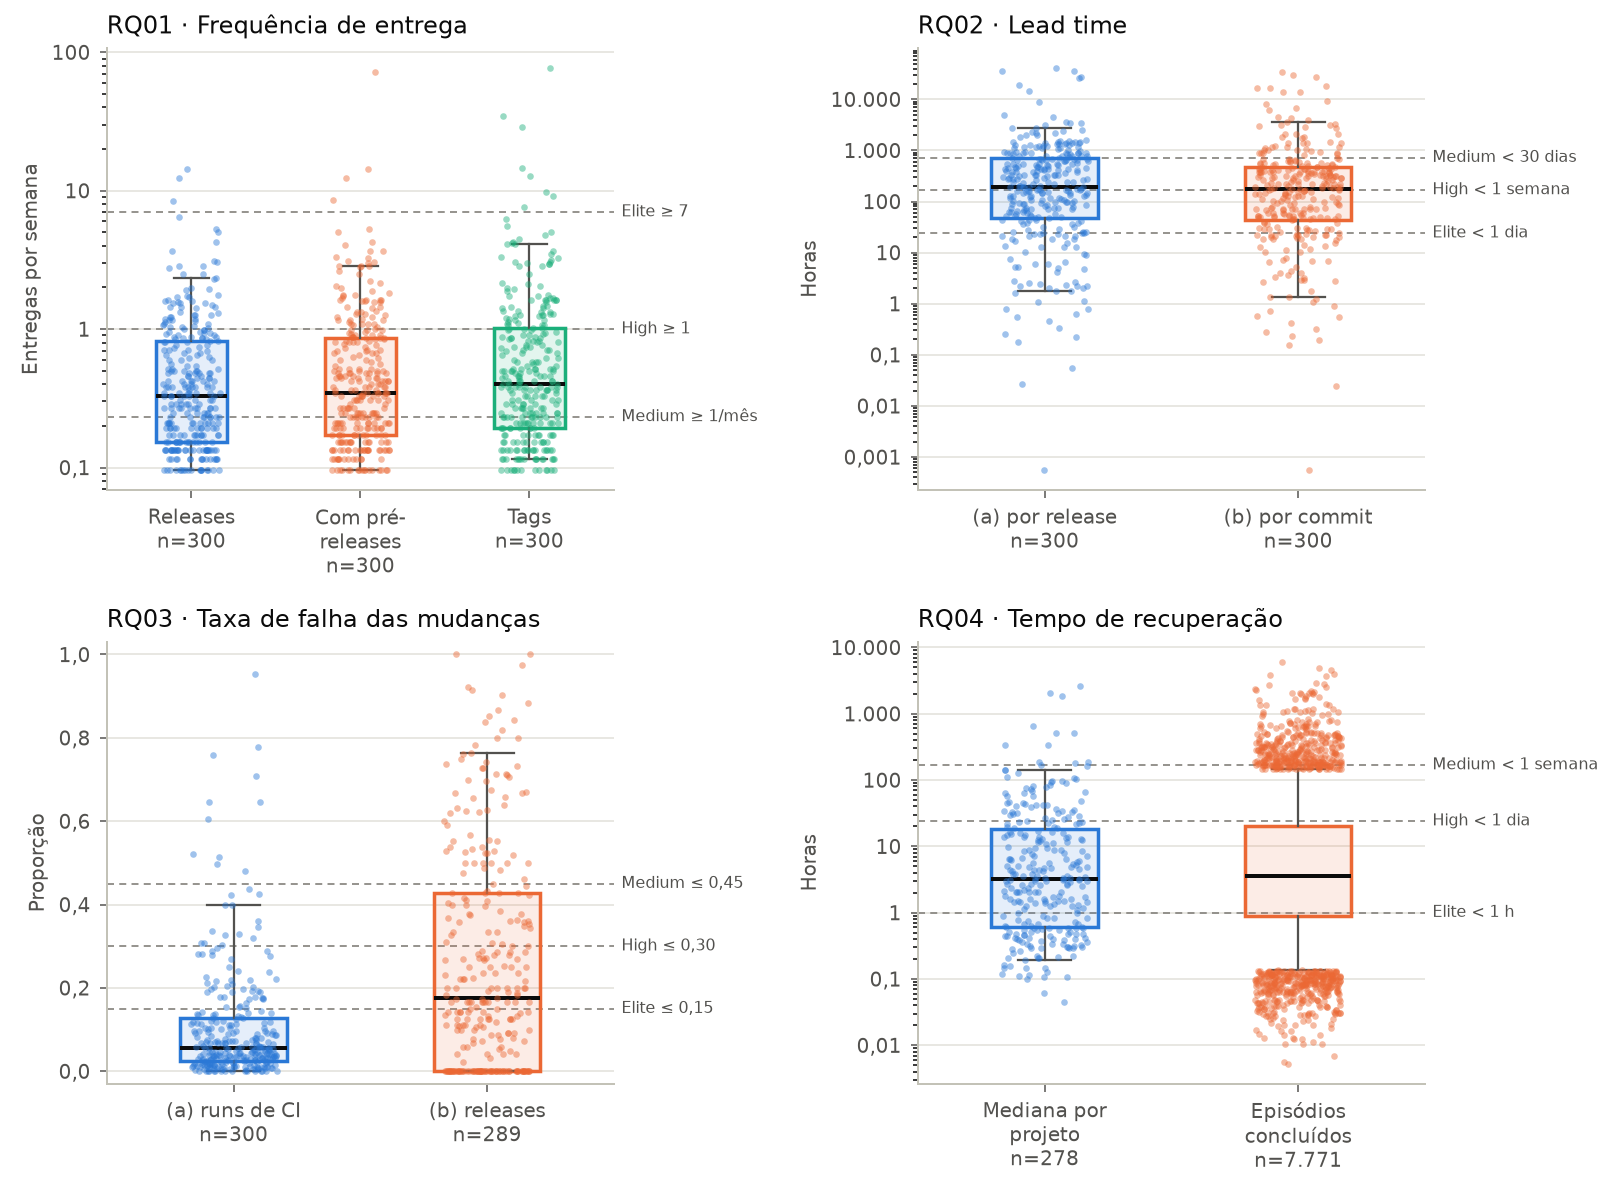

In [3]:
display(Image(filename=str(PUBLICADOS / "rq01_04_distribuicoes.png")))

## Variantes no mesmo projeto

Diferença $x - y$ por projeto. O teste de Wilcoxon pareado (bilateral, sem as diferenças
nulas) e a correlação rank-biserial $r$ entram só nas comparações ligadas a hipóteses (H2 e H3);
os dois p-valores são ajustados juntos por Holm. As variantes de frequência são descritivas:
com pré-releases é, por construção, um superconjunto das releases.

In [4]:
colunas = ["hipotese", "x", "y", "n", "n_x_maior", "n_iguais", "n_x_menor", "mediana_diferenca",
           "mediana_razao", "efeito_rank_biserial", "p_holm"]
tabelas["rq01_04_pareadas"][colunas]

,hipotese,x,y,n,n_x_maior,n_iguais,n_x_menor,mediana_diferenca,mediana_razao,efeito_rank_biserial,p_holm
0,,deployment_frequency_prereleases,deployment_frequency,300,87,213,0,0.000000,1.000000,NaN,NaN
1,,deployment_frequency_tags,deployment_frequency,300,162,135,3,0.019178,1.022365,NaN,NaN
2,H2,lead_time_a_horas,lead_time_b_horas,300,191,2,107,24.841250,1.491628,0.325447,1.118911e-06
3,H3,cfr_a,cfr_b,289,101,2,186,-0.108608,NaN,-0.554104,8.134298e-16


## RQ04: censura

Proporção de episódios censurados e um limite simples para o seu efeito: a mediana no
"pior caso" supõe que cada episódio censurado dure mais que todos os concluídos.

In [5]:
tabelas["rq04_censura"].assign(valor=lambda t: t.valor.round(4))

,indicador,valor,descricao
0,episodios_total,7861.0000,Episódios de falha abertos após um sucesso
1,episodios_concluidos,7771.0000,Episódios encerrados por um sucesso posterior
2,episodios_censurados,90.0000,Episódios sem sucesso posterior até o fim dos ...
3,proporcao_episodios_censurados,0.0114,episodios_censurados / episodios_total
4,repositorios,300.0000,Projetos da amostra
5,repositorios_com_episodios,278.0000,Projetos com ao menos um episódio
6,repositorios_sem_episodios,22.0000,Projetos sem episódio observável; recuperação ...
7,repositorios_somente_censurados,0.0000,Projetos cujos episódios estão todos censurados
8,repositorios_com_censura,61.0000,Projetos com ao menos um episódio censurado
9,proporcao_repositorios_com_censura,0.2194,repositorios_com_censura / repositorios_com_ep...


In [6]:
por_repo = df.loc[df.episodios_censurados > 0, ["full_name", "episodios_total", "episodios_censurados",
                                                  "proporcao_censurados"]]
por_repo.sort_values("proporcao_censurados", ascending=False).head(10)

,full_name,episodios_total,episodios_censurados,proporcao_censurados
13,F0x1d/LogFox,2,1,0.500000
61,ada-url/ada,39,14,0.358974
59,a2aproject/a2a-python,5,1,0.200000
185,mainmatter/ember-simple-auth,5,1,0.200000
179,libp2p/go-libp2p,10,2,0.200000
128,ev-flow/quark-engine,6,1,0.166667
214,obgnail/typora_plugin,6,1,0.166667
239,qiz029/dscode,13,2,0.153846
145,googleapis/go-genai,7,1,0.142857
57,Ylianst/MeshCentral,7,1,0.142857


## Respostas e hipóteses

| RQ | Hipótese | Resultado |
|---|---|---|
| RQ01 | H1: mediana abaixo de 1 release/semana, com cauda longa | **Sustentada.** Mediana de 0,326 release/semana (Q1–Q3: 0,153–0,825); 56 projetos (18,7%) publicam ao menos uma por semana e só 3 chegam a 7 ou mais. Incluir pré-releases ou usar tags desloca pouco a mediana (0,345 e 0,403). |
| RQ02 | H2: lead time (a) bem maior que (b) | **Parcialmente sustentada.** (a) supera (b) em 191 de 300 projetos (Wilcoxon, p Holm ≈ 1,1×10⁻⁶; r = 0,33), mas as medianas são próximas: 196,7 h contra 178,3 h; razão mediana de 1,49 por projeto. |
| RQ03 | H3: CFR (a), de CI, maior que CFR (b), de releases | **Não sustentada; ocorre o inverso.** CFR (a) mediano de 0,055 contra 0,175 do CFR (b); (b) é maior em 186 de 289 projetos (r = −0,55). O CFR (b) também é mais disperso: 74 projetos têm zero e o Q3 é 0,429. |
| RQ04 | H4: poucas horas, cauda pesada e censura não desprezível | **Parcialmente sustentada.** Mediana por projeto de 3,20 h (0,60–18,37) e cauda pesada (P90 dos episódios de 73,4 h; 4,2% duram uma semana ou mais), mas só 1,1% dos 7.861 episódios são censurados; no pior caso a mediana passaria de 3,57 h para 3,66 h. |

Os números desta tabela vêm das células acima; se o dataset mudar, a conferência inicial falha
antes de qualquer texto ser reaproveitado.